In [1]:
import xcs_code_stockpile as xcs
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
proposal_number = 101927227  # noqa
run = 38  # noqa

In [3]:
h5 = xcs.load_smalldata(run, proposal_number)
h5dict = xcs.H5Dictionary(
    stack='/jungfrau1M/ROI_area',
    i0=lambda h5: h5['diodeGon/channels'][..., 0],
    laser_on=lambda h5: np.zeros(h5['event_time'].shape, dtype=bool),
    att='epics/att_T'
)

In [4]:
metadata = xcs.create_metadata(h5, run, h5dict, roi=None)
valid = xcs.sensible_filter(metadata, 0.5, 99.5, 0.5, 99.5)

Didn't find the key delay...


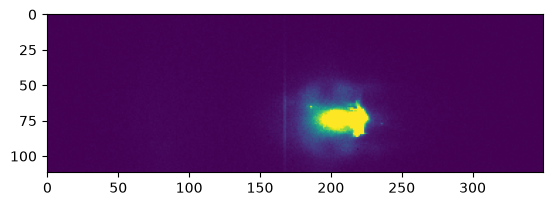

In [5]:
xcs.plot_detector_image(h5, h5dict, samplerate=100).show()

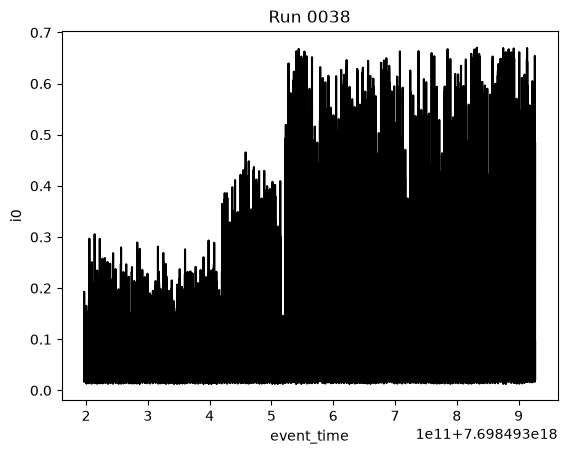

In [6]:
xcs.plot_i0_vs_time(metadata, valid).show()

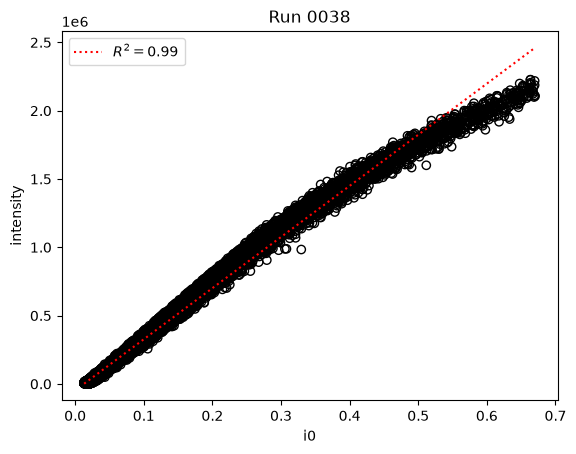

In [7]:
xcs.plot_intensity_vs_i0(metadata, valid).show()

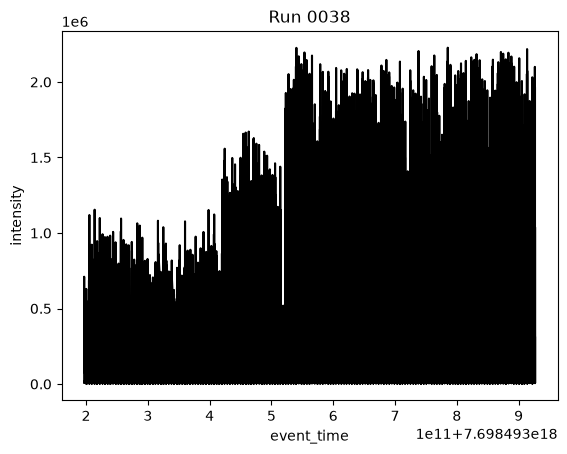

In [8]:
xcs.plot_intensity_vs_time(metadata, valid).show()

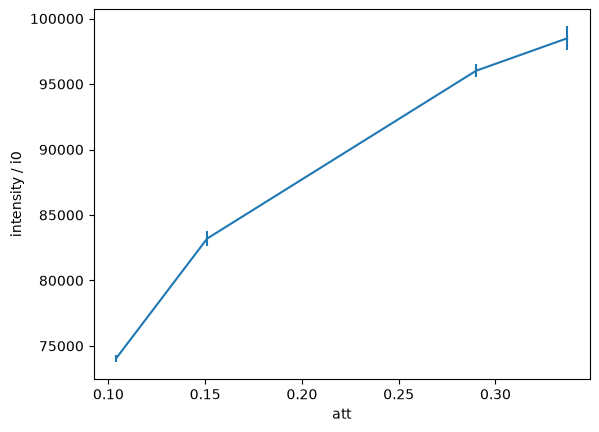

In [9]:
metadata['att_bin'] = pd.cut(metadata['att'], 6)
rocking = xcs.calc_rocking_stats(h5, h5dict, 'att_bin', metadata, valid, roi=None)
rocking.index = [bin.left for bin in rocking.index]
plt.errorbar(rocking.index.to_numpy(), rocking['intensity_mean'].to_numpy(), rocking['intensity_stderr'].to_numpy())
plt.xlabel('att')
plt.ylabel('intensity / i0')
plt.show()